In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 2.3 — Composition and tensor expressions

**Source:** SMSA 7.8, 2026-11-05, §2.3, equations (2.18)–(2.25), (2.28)–(2.37), (2.39)–(2.40), (2.43)–(2.44), (2.52)–(2.58), pp. 63–71, 77–78. Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

Read the two consecutive coupons as `f >> g`. A single named coupon `gf` is assigned the matrix of the composite. The free syntax retains two coupons versus one; the tensor functor evaluates both to the same linear map. The small integer matrices below are an illustrative specialization, not matrices copied from SMSA. DisCoPy stores input indices before output indices, so a conventional column-vector matrix is transposed when supplied to this functor.

In [1]:
from discopy import symmetric, tensor
from discopy.drawing import Equation
import numpy as np

In [2]:
U, V, W = map(symmetric.Ty, ['U', 'V', 'W'])
f = symmetric.Box('f', U, V)
g = symmetric.Box('g', V, W)
gf = symmetric.Box('g o f', U, W)
M_f = np.array([[1, 2], [0, 1]])
M_g = np.array([[2, 0], [1, 3]])
F = tensor.Functor({U: 2, V: 2, W: 2}, {f: M_f.T, g: M_g.T, gf: (M_g @ M_f).T}, dom=symmetric.Category(), dtype=int)

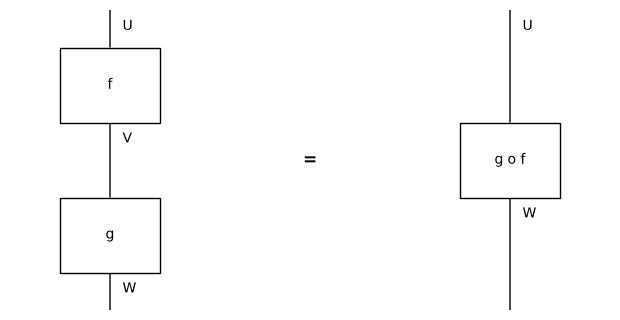

In [3]:
Equation(f >> g, gf).draw(figsize=(6, 3))

In [4]:
print('(2.24) computed column-matrix:\n', F(f >> g).array.T)
print('Expected M_g @ M_f:\n', M_g @ M_f)
print('Equal tensor values:', F(f >> g) == F(gf))
print('Free diagrams identical:', (f >> g) == gf)

(2.24) computed column-matrix:
 [[2 4]
 [1 5]]
Expected M_g @ M_f:
 [[2 4]
 [1 5]]
Equal tensor values: True
Free diagrams identical: False


Tensor product domain: U @ V ; codomain: V @ W
Computed tensor-product matrix:
 [[2 0 4 0]
 [1 3 2 6]
 [0 0 2 0]
 [0 0 1 3]]
Expected Kronecker matrix:
 [[2 0 4 0]
 [1 3 2 6]
 [0 0 2 0]
 [0 0 1 3]]
Match: True


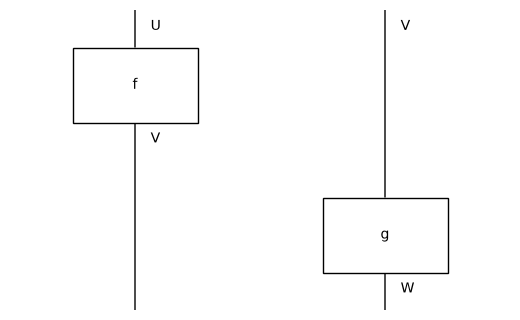

In [5]:
parallel = f @ g
parallel.draw(figsize=(5, 3))
print('Tensor product domain:', parallel.dom, '; codomain:', parallel.cod)
print('Computed tensor-product matrix:\n', F(parallel).array.reshape(4, 4).T)
print('Expected Kronecker matrix:\n', np.kron(M_f, M_g))
print('Match:', np.array_equal(F(parallel).array.reshape(4, 4).T, np.kron(M_f, M_g)))

### Reading a basis index

For (2.18)–(2.23), choose $v=(2,-1)$ in a two-dimensional space and
$A=\begin{pmatrix}1&2\\-1&3\\4&0\end{pmatrix}$ mapping it to a three-dimensional space. These numbers are chosen here. The output component is $(Av)^a=\sum_i A^a{}_i v^i$. A wire without a coupon gives the identity coefficients $\delta^a{}_i$. DisCoPy's array for this coupon has axes **input $i$, output $a$**, hence contains $A^T$. This is storage order, not a change in the map.


A type: P -> Q ; array axes (i,a): (2, 3)
Array A[i,a]:
 [[ 1 -1  4]
 [ 2  3  0]]
Av actual: [ 0 -5  8] ; expected: [ 0 -5  8]
Match: True
Identity array, expected delta[i,j]:
 [[1 0]
 [0 1]]
Delta match: True


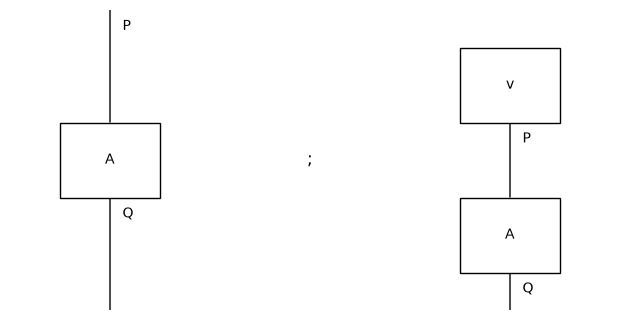

In [6]:
P, Q = map(symmetric.Ty, ['P', 'Q'])
A_box = symmetric.Box('A', P, Q)
v_box = symmetric.Box('v', symmetric.Ty(), P)
A_values = np.array([[1, 2], [-1, 3], [4, 0]])
v_values = np.array([2, -1])
a_values = np.array([3, 1])
b_values = np.array([1, -2, 3])
a_box = symmetric.Box('a', P, symmetric.Ty())
b_box = symmetric.Box('b', Q, symmetric.Ty())
F_basis = tensor.Functor({P: 2, Q: 3}, {A_box: A_values.T, v_box: v_values, a_box: a_values, b_box: b_values}, dom=symmetric.Category(), dtype=int)
Equation(A_box, v_box >> A_box, symbol=";").draw(figsize=(6, 3))
print('A type:', A_box.dom, '->', A_box.cod, '; array axes (i,a):', F_basis(A_box).array.shape)
print('Array A[i,a]:\n', F_basis(A_box).array)
print('Av actual:', F_basis(v_box >> A_box).array, '; expected:', A_values @ v_values)
print('Match:', np.array_equal(F_basis(v_box >> A_box).array, A_values @ v_values))
print('Identity array, expected delta[i,j]:\n', F_basis(symmetric.Id(P)).array)
print('Delta match:', np.array_equal(F_basis(symmetric.Id(P)).array, np.eye(2, dtype=int)))


### Empty boundaries, scalars and two outputs

A state $v:\mathbb F\to P$, a covector $a:P\to\mathbb F$, and a scalar $a(v):\mathbb F\to\mathbb F$ have respectively zero, one and zero input wires, as in (2.28)–(2.33). The empty type stands for $\mathbb F$. Here $a(v)=5$ and $b(Av)=34$.

The same pair $v,a$ gives two different compositions in (2.43)–(2.44). Reading from the inputs, $v\mathbin{>>}a$ is the scalar $a(v)$, whereas $a\mathbin{>>}v:P\to P$ is the rank-one map $v a$. Its conventional matrix has output index first.

For (2.39)–(2.40), the state $C:\mathbb F\to P\otimes Q$ below has a freely chosen $2\times3$ coefficient array. A product of two states has coefficients $v^i w^a$. The displayed nonzero $2\times2$ minor of $C$ shows that this particular $C$ cannot be such a product. These are linear-algebra examples, without quantum-state normalization assumptions.


Scalar type: Ty() -> Ty()
a(v): 5 ; expected: 5
b(Av): 34 ; expected: 34
Outer map type: P -> P
Outer map, output,input matrix:
 [[ 6  2]
 [-3 -1]]
Expected v outer a:
 [[ 6  2]
 [-3 -1]]
Outer match: True
C type: Ty() -> P @ Q ; axes (i,a):
 [[ 1  2  0]
 [-1  3  4]]
Product axes (i,a), actual:
 [[ 2 -4  6]
 [-1  2 -3]]
Expected v[i]w[a]:
 [[ 2 -4  6]
 [-1  2 -3]]
Product match: True
First 2x2 minor of C: 5 ; product minor: 0


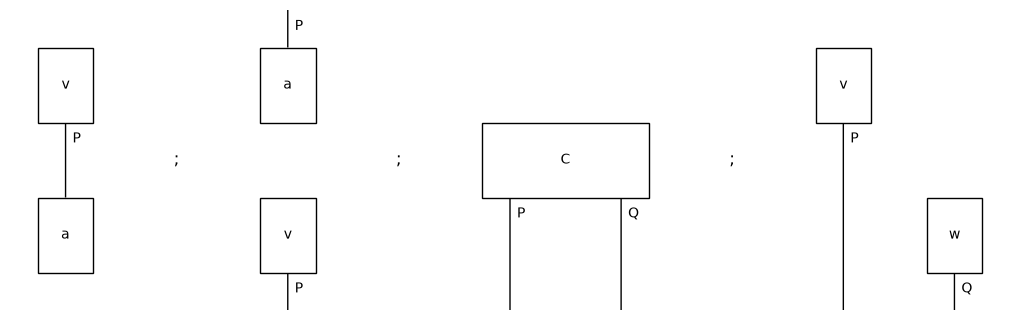

In [7]:
w_box = symmetric.Box('w', symmetric.Ty(), Q)
C_box = symmetric.Box('C', symmetric.Ty(), P @ Q)
w_values = np.array([1, -2, 3])
C_values = np.array([[1, 2, 0], [-1, 3, 4]])
F_states = tensor.Functor({P: 2, Q: 3}, {v_box: v_values, a_box: a_values, w_box: w_values, C_box: C_values}, dom=symmetric.Category(), dtype=int)
Equation(v_box >> a_box, a_box >> v_box, C_box, v_box @ w_box, symbol=";").draw(figsize=(10, 3))
print('Scalar type:', (v_box >> a_box).dom, '->', (v_box >> a_box).cod)
print('a(v):', F_states(v_box >> a_box).array, '; expected:', a_values @ v_values)
print('b(Av):', F_basis(v_box >> A_box >> b_box).array, '; expected:', b_values @ A_values @ v_values)
print('Outer map type:', (a_box >> v_box).dom, '->', (a_box >> v_box).cod)
print('Outer map, output,input matrix:\n', F_states(a_box >> v_box).array.T)
print('Expected v outer a:\n', np.outer(v_values, a_values))
print('Outer match:', np.array_equal(F_states(a_box >> v_box).array.T, np.outer(v_values, a_values)))
print('C type:', C_box.dom, '->', C_box.cod, '; axes (i,a):\n', F_states(C_box).array)
print('Product axes (i,a), actual:\n', F_states(v_box @ w_box).array)
print('Expected v[i]w[a]:\n', np.outer(v_values, w_values))
print('Product match:', np.array_equal(F_states(v_box @ w_box).array, np.outer(v_values, w_values)))
print('First 2x2 minor of C:', C_values[0, 0]*C_values[1, 1] - C_values[0, 1]*C_values[1, 0], '; product minor: 0')


### Three contracted indices: (2.36)–(2.37)

Use precisely the source network, with $f:V_3\to U_2\otimes U_3\otimes W_2$, $g:V_1\otimes V_2\otimes U_2\to W_1\otimes U_1$, and $h:U_1\otimes U_3\to\mathbb F$. The dimensions of $V_1,V_2,V_3,U_2,W_2,W_1,U_1$ are all 2, and $\dim U_3=3$. Integers generated below are chosen examples, not SMSA data.

With input indices first, the three arrays have axes $f[q,m,n,p]$, $g[k,l,m,i,j]$, $h[j,n]$. The external axes are $[k,l,q,i,p]$, in the order $V_1,V_2,V_3,W_1,W_2$. Thus (2.37) says
$$T[k,l,q,i,p]=\sum_{j,m,n}g[k,l,m,i,j]f[q,m,n,p]h[j,n].$$
Python indices start at zero, unlike the source's indices starting at one. The native drawing reverses the source's vertical reading direction, while keeping the same left-to-right wires and contracted slots.


External type: V1 @ V2 @ V3 -> W1 @ W2
Array axes (k,l,q,i,p): (2, 2, 2, 2, 2)
Actual slice k=l=q=0, axes (i,p):
 [[ 22 -24]
 [  5  15]]
Expected slice:
 [[ 22 -24]
 [  5  15]]
Actual slice k=1,l=0,q=1:
 [[-10  24]
 [-34 -34]]
Expected slice:
 [[-10  24]
 [-34 -34]]
All 32 coefficients match: True
Wrong V1/V2 input routing, same slice k=1,l=0,q=1:
 [[-34 -34]
 [ 37  33]]
Wrong routing agrees with (2.37): False


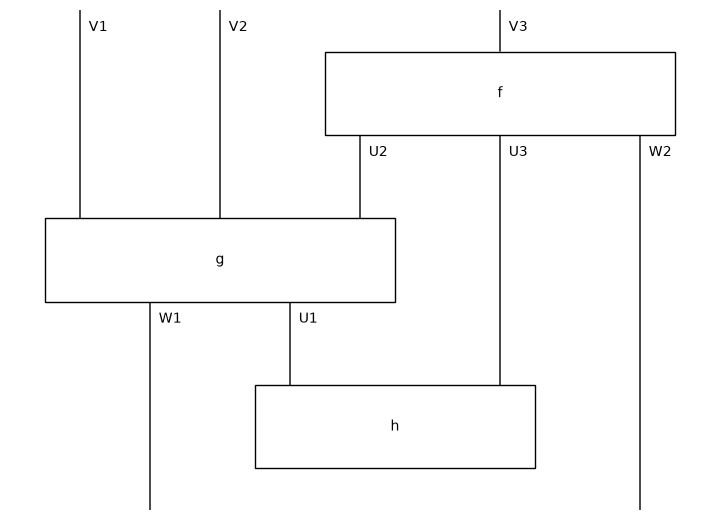

In [8]:
V1, V2, V3, U1, U2, U3, W1, W2 = map(symmetric.Ty, ['V1', 'V2', 'V3', 'U1', 'U2', 'U3', 'W1', 'W2'])
f_contract = symmetric.Box('f', V3, U2 @ U3 @ W2)
g_contract = symmetric.Box('g', V1 @ V2 @ U2, W1 @ U1)
h_contract = symmetric.Box('h', U1 @ U3, symmetric.Ty())
f_values = np.arange(24).reshape(2, 2, 3, 2) % 7 - 3
g_values = np.arange(32).reshape(2, 2, 2, 2, 2) % 5 - 2
h_values = np.array([[1, 2, 0], [-1, 3, 4]])
F_contract = tensor.Functor({V1: 2, V2: 2, V3: 2, U1: 2, U2: 2, U3: 3, W1: 2, W2: 2}, {f_contract: f_values, g_contract: g_values, h_contract: h_values}, dom=symmetric.Category(), dtype=int)
contraction = (symmetric.Id(V1 @ V2) @ f_contract) >> (g_contract @ symmetric.Id(U3 @ W2)) >> (symmetric.Id(W1) @ h_contract @ symmetric.Id(W2))
contraction.draw(figsize=(7, 5))
contraction_array = F_contract(contraction).array
contraction_expected = np.einsum('klmij,qmnp,jn->klqip', g_values, f_values, h_values)
print('External type:', contraction.dom, '->', contraction.cod)
print('Array axes (k,l,q,i,p):', contraction_array.shape)
print('Actual slice k=l=q=0, axes (i,p):\n', contraction_array[0, 0, 0])
print('Expected slice:\n', contraction_expected[0, 0, 0])
print('Actual slice k=1,l=0,q=1:\n', contraction_array[1, 0, 1])
print('Expected slice:\n', contraction_expected[1, 0, 1])
print('All 32 coefficients match:', np.array_equal(contraction_array, contraction_expected))
wrong_g_values = g_values.swapaxes(0, 1)
F_wrong_inputs = tensor.Functor({V1: 2, V2: 2, V3: 2, U1: 2, U2: 2, U3: 3, W1: 2, W2: 2}, {f_contract: f_values, g_contract: wrong_g_values, h_contract: h_values}, dom=symmetric.Category(), dtype=int)
wrong_input_array = F_wrong_inputs(contraction).array
print('Wrong V1/V2 input routing, same slice k=1,l=0,q=1:\n', wrong_input_array[1, 0, 1])
print('Wrong routing agrees with (2.37):', np.array_equal(wrong_input_array, contraction_expected))


### Group elements as wire labels: (2.52)–(2.56)

In §2.3.c the wires carry group elements instead of vector indices, and (2.52) replaces the coupon $\mu$ by a dot. The companion reads a label $g$ as the basis vector $b_g$ of the group algebra (§3.1.8): the picture with $g,g'$ at the bottom and $g\cdot g'$ at the top says that `mu` sends $b_g\otimes b_{g'}$ to the single basis vector $b_{g g'}$. Take $G=\mathbb Z_3$ written additively, labels $0,1,2$ with $e=0$. A labelled input is a state box with no input wire, as in (2.28). The coupon `mu` keeps its name; the dot of (2.52) is SMSA's abbreviation for it. The chosen group is an example; the arrays are the multiplication table, not data copied from SMSA.

(2.52) with g=1, g'=2: output coefficients on b_0, b_1, b_2: [1 0 0]
Expected b_(1+2 mod 3) = b_0: [1 0 0] ; match: True


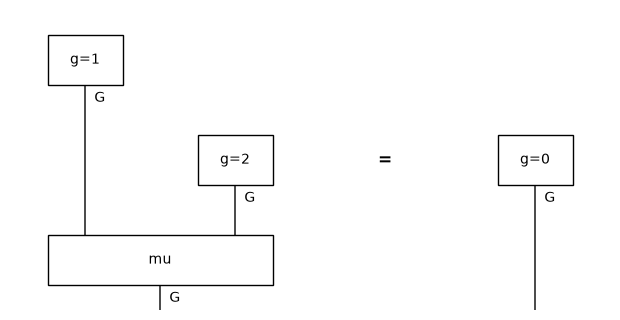

In [9]:
G = symmetric.Ty('G')
mu_G = symmetric.Box('mu', G @ G, G)
eta_G = symmetric.Box('eta', symmetric.Ty(), G)
labels = [symmetric.Box(f'g={k}', symmetric.Ty(), G) for k in range(3)]
I_G = symmetric.Id(G)
F_Z3 = tensor.Functor({G: 3},
    {mu_G: [[[int(k == (i + j) % 3) for k in range(3)] for j in range(3)] for i in range(3)],
     eta_G: [1, 0, 0], **{labels[k]: [int(m == k) for m in range(3)] for k in range(3)}},
    dom=symmetric.Category(), dtype=int)
product_12 = (labels[1] @ labels[2]) >> mu_G
Equation(product_12, labels[0], symbol='=').draw(figsize=(6, 3))
print("(2.52) with g=1, g'=2: output coefficients on b_0, b_1, b_2:", F_Z3(product_12).array)
print('Expected b_(1+2 mod 3) = b_0:', F_Z3(labels[0]).array, '; match:', np.array_equal(F_Z3(product_12).array, F_Z3(labels[0]).array))


Associativity (2.53) holds for all triples of labels. The unlabelled form (2.55) is the array identity (2.57): the arrays of `mu` carry every label at once, so one comparison covers all $27$ triples. Two labelled triples are then drawn and evaluated, with the left tree `(mu @ I) >> mu` and the right tree `(I @ mu) >> mu`. For the unit law (2.54), the coefficient of $\mu(b_e\otimes b_g)$ on $b_{g'}$ is the symbol $\delta_{g',g}$ of SMSA; the printed matrix has rows $g$ and columns $g'$. The map $\eta$ of (2.56) is the state $b_e$, which is the `eta` of §3.1.

(2.55) as (2.57) on all 27 triples, largest |left - right|: 0 ; equal: True
(2.53) labels (1,2,2): left tree [0 0 1] ; right tree [0 0 1] ; expected b_2
(2.53) labels (2,2,1): left tree [0 0 1] ; right tree [0 0 1] ; expected b_2
(2.54) coefficient of mu(b_e, b_g) on b_g', rows g, columns g':
 [[1 0 0]
 [0 1 0]
 [0 0 1]]
Equals delta_{g',g}: True ; right unit too: True
(2.56) eta as the state b_e: [1 0 0] ; equals the label e=0 state: True


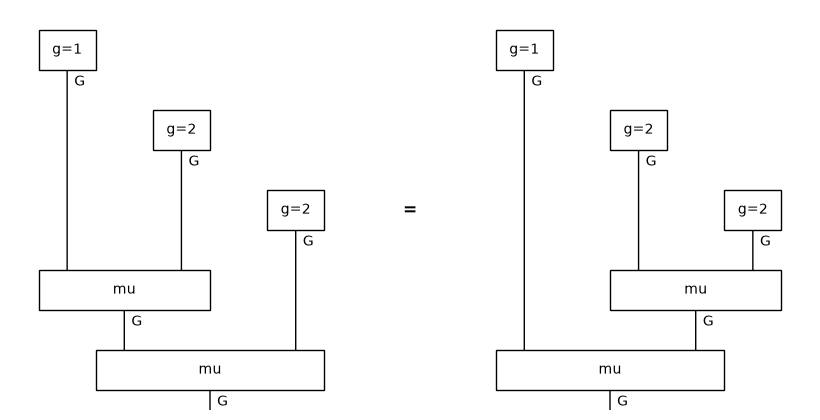

In [10]:
assoc_left = (mu_G @ I_G) >> mu_G
assoc_right = (I_G @ mu_G) >> mu_G
print('(2.55) as (2.57) on all 27 triples, largest |left - right|:', np.abs(F_Z3(assoc_left).array - F_Z3(assoc_right).array).max(), '; equal:', np.array_equal(F_Z3(assoc_left).array, F_Z3(assoc_right).array))
for g0, g1, g2 in [(1, 2, 2), (2, 2, 1)]:
    triple = labels[g0] @ labels[g1] @ labels[g2]
    print(f"(2.53) labels ({g0},{g1},{g2}): left tree", F_Z3(triple >> assoc_left).array, '; right tree', F_Z3(triple >> assoc_right).array, '; expected b_' + str((g0 + g1 + g2) % 3))
triple_122 = labels[1] @ labels[2] @ labels[2]
Equation(triple_122 >> assoc_left, triple_122 >> assoc_right, symbol='=').draw(figsize=(8, 4))
delta_left = np.array([[F_Z3((eta_G @ labels[g]) >> mu_G).array[h] for h in range(3)] for g in range(3)])
delta_right = np.array([[F_Z3((labels[g] @ eta_G) >> mu_G).array[h] for h in range(3)] for g in range(3)])
print("(2.54) coefficient of mu(b_e, b_g) on b_g', rows g, columns g':\n", delta_left)
print("Equals delta_{g',g}:", np.array_equal(delta_left, np.eye(3, dtype=int)), '; right unit too:', np.array_equal(delta_right, np.eye(3, dtype=int)))
print('(2.56) eta as the state b_e:', F_Z3(eta_G).array, '; equals the label e=0 state:', np.array_equal(F_Z3(eta_G).array, F_Z3(labels[0]).array))


**Scope and further pictures.** These chosen finite arrays translate the linear-map, state, scalar, tensor-product and contraction pictures above. The epsilon tensor for the cross-product picture (2.41) is treated in `smsa_17_06.ipynb`; the interchange pictures (2.45)–(2.46) in `smsa_17_01.ipynb`. The group-labelled pictures of §2.3.c are read above as basis vectors of the group algebra; the inverse axioms, which SMSA postpones there, are the antipode pictures of `smsa_03_02.ipynb`. The homework network (2.38) and homework §2.3.42 are left for the reader.
